In [38]:
# Librerías necesarias
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
import matplotlib.pyplot as plt
import os

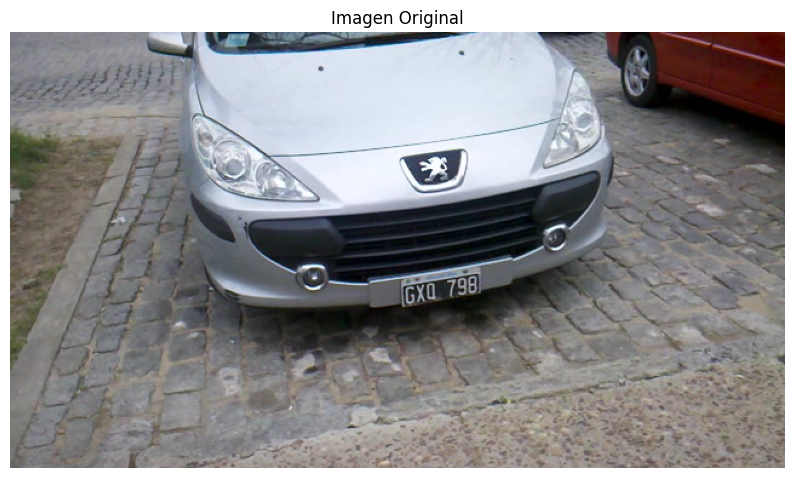

In [39]:
# Cargamos la imagen original
imagen = cv2.imread('/content/drive/MyDrive/Colab Notebooks/PDI/TP_2/img02.png')
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
plt.title('Imagen Original')
plt.axis('off')
plt.show()


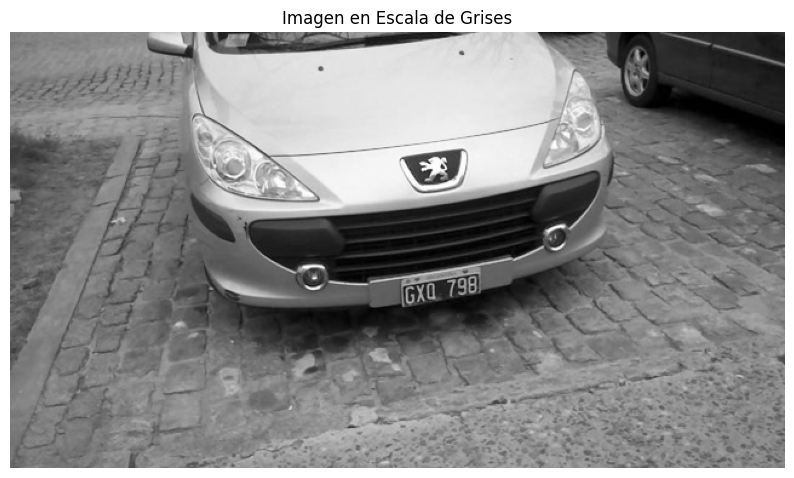

In [40]:
# Convertimos a escala de grises
imagen_gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)
plt.figure(figsize=(10, 10))
plt.imshow(imagen_gris, cmap='gray')
plt.title('Imagen en Escala de Grises')
plt.axis('off')
plt.show()



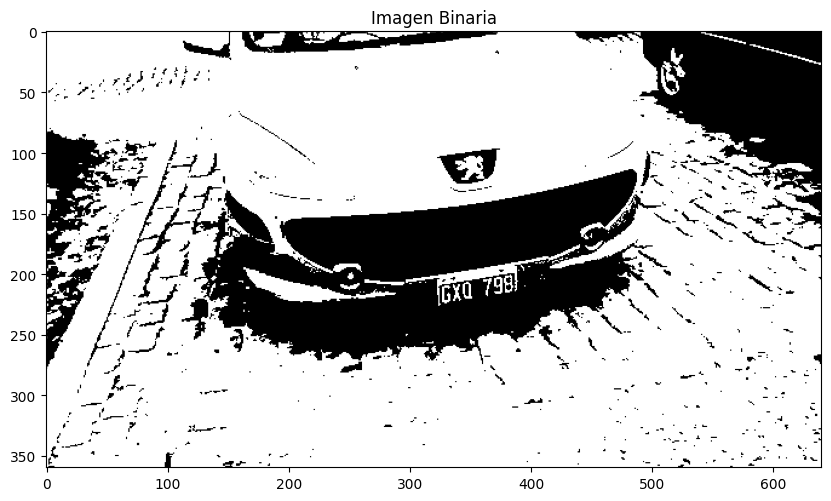

In [44]:
# Umbralamos para aislar la patente en negro/blanco
_, imagen_binaria = cv2.threshold(imagen_gris, 100, 255, cv2.THRESH_BINARY)
plt.figure(figsize=(10, 10))
plt.imshow(imagen_binaria, cmap='gray')
plt.title('Imagen Binaria')
#plt.axis('off')
plt.show()


140
Etiqueta 77: Área 60 Bbox -> Base: 8 Altura:15
Etiqueta 83: Área 60 Bbox -> Base: 7 Altura:14
Etiqueta 87: Área 36 Bbox -> Base: 7 Altura:15
Etiqueta 95: Área 59 Bbox -> Base: 8 Altura:14
Etiqueta 101: Área 49 Bbox -> Base: 7 Altura:14
Etiqueta 106: Área 60 Bbox -> Base: 7 Altura:15


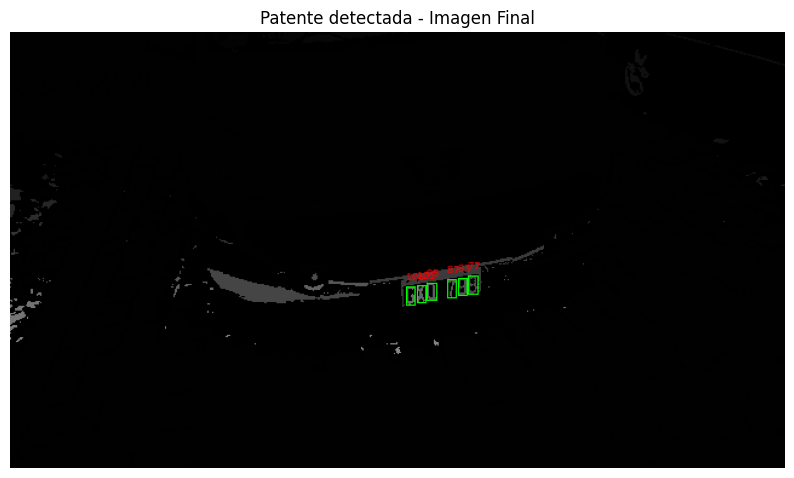

In [59]:
# Aplicamos componentes conectadas
# Filtramos las etiquetas con Area mayor a 35 y menor a 70
num_etiquetas, etiquetas, stats, _ = cv2.connectedComponentsWithStats(imagen_binaria, connectivity=8)
etiquetas_color = cv2.cvtColor(etiquetas.astype(np.uint8), cv2.COLOR_GRAY2BGR)
print(num_etiquetas)

for i in range(1, num_etiquetas):
    x, y, w, h, area = stats[i]
    # Filtramos por área y relación de aspecto
    if area > 30 and area < 70:
        if h/w > 1.5 and h/w < 2.2:
            # Bounding box color verde (0, 255, 0) con grosor fino 1
            cv2.rectangle(etiquetas_color, (x, y), (x + w, y + h), (0, 255, 0), 1)
            # Texto/Etiquetas color rojo (0, 0, 255) en formato BGR
            cv2.putText(etiquetas_color, str(i), (x, y - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.3, (0, 0, 255), 1)
            print(f"Etiqueta {i}: Área {area} Bbox -> Base: {w} Altura:{h}")

# Mostramos únicamente la imagen final con todas las detecciones aplicadas
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(etiquetas_color, cv2.COLOR_BGR2RGB))
plt.title('Patente detectada - Imagen Final')
plt.axis('off')
plt.show()